In [1]:
import csv
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pasta = Path("datasets")
arquivos = [pasta / "CAT_2026" / f"D.SDA.PDA.005.CAT.2026{mes:02}.csv" for mes in range(1, 7)]
inicio, fim = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-06-30")
pd.set_option("display.max_colwidth", None)

campos = [
    "agente", "data_acidente", "cbo", "cbo_descricao", "cid", "cid_descricao",
    "cnae", "cnae_descricao", "emitente", "especie_beneficio", "filiacao", "obito",
    "municipio_empregador", "natureza_lesao", "origem_cadastro", "parte_atingida",
    "sexo", "tipo", "uf_acidente", "uf_empregador", "data_afastamento",
    "data_despacho", "data_acidente_2", "data_nascimento", "data_emissao",
    "tipo_empregador", "cnpj_cei",
]
cabecalho_esperado = (
    "Agente Causador Acidente;Data Acidente;CBO;CBO;CID-10;CID-10;"
    "CNAE2.0 Empregador;CNAE2.0 Empregador;Emitente CAT;Espécie do benefício;"
    "Filiação Segurado;Indica Óbito Acidente;Munic Empr;Natureza da Lesão;"
    "Origem de Cadastramento CAT;Parte Corpo Atingida;Sexo;Tipo do Acidente;"
    "UF Munic. Acidente;UF Munic. Empregador;Data Afastamento;Data Despacho Benefício;"
    "Data Acidente;Data Nascimento;Data Emissão CAT;Tipo de Empregador;CNPJ/CEI Empregador"
).split(";")

partes = []
for caminho in arquivos:
    with caminho.open(encoding="latin-1", newline="") as entrada:
        cabecalho = next(csv.reader(entrada, delimiter=";"))
    if [" ".join(nome.split()) for nome in cabecalho] != cabecalho_esperado:
        raise ValueError(f"Esquema inesperado em {caminho.name}.")
    dados = pd.read_csv(caminho, sep=";", encoding="latin-1", dtype=str,
                        keep_default_na=False, header=0, names=campos, skip_blank_lines=False)
    dados["arquivo_origem"] = caminho.name
    dados["linha_origem"] = range(2, len(dados) + 2)
    partes.append(dados)

brutos = pd.concat(partes, ignore_index=True)
del dados, partes
assert not brutos.duplicated(["arquivo_origem", "linha_origem"]).any()
por_arquivo = brutos.groupby("arquivo_origem", sort=True)
inventario = por_arquivo.size().to_frame("Linhas")
inventario["Campos de origem"] = len(campos)
inventario.loc["Total"] = [len(brutos), len(campos)]
display(inventario)

,Linhas,Campos de origem
arquivo_origem,,
D.SDA.PDA.005.CAT.202601.csv,53595,27
D.SDA.PDA.005.CAT.202602.csv,65622,27
D.SDA.PDA.005.CAT.202603.csv,72021,27
D.SDA.PDA.005.CAT.202604.csv,74363,27
D.SDA.PDA.005.CAT.202605.csv,214049,27
D.SDA.PDA.005.CAT.202606.csv,140513,27
Total,620163,27


In [2]:
marcadores = {
    "cbo": ["000000"], "cnae": ["0000"], "municipio_empregador": ["000000-ignorado"],
    "uf_empregador": ["zerado"], "uf_acidente": ["zerado"],
    "sexo": ["indeterminado", "não informado"],
}

def perfil_campos(dados):
    linhas = []
    for campo in campos:
        texto = dados[campo].str.strip().str.lower()
        linhas.append({
            "Campo": campo, "Valores distintos": texto.nunique(), "Vazio": texto.eq("").sum(),
            "{ñ class}": texto.eq("{ñ class}").sum(), "00/00/0000": texto.eq("00/00/0000").sum(),
            "Outro marcador": texto.isin(marcadores.get(campo, [])).sum(),
        })
    return pd.DataFrame(linhas).set_index("Campo")

perfil = perfil_campos(brutos)
esquema = perfil.copy()
esquema.insert(0, "Cabeçalho original", cabecalho)
esquema.insert(0, "Posição", range(1, len(campos) + 1))
esquema.insert(2, "Tipo lido", brutos[campos].dtypes.astype(str))
display(esquema)

,Posição,Cabeçalho original,Tipo lido,Valores distintos,Vazio,{ñ class},00/00/0000,Outro marcador
Campo,,,,,,,,
agente,1,Agente Causador Acidente,str,274,0,3903,0,0
data_acidente,2,Data Acidente,str,213,0,0,0,0
cbo,3,CBO,str,2152,0,0,0,9
cbo_descricao,4,CBO,str,1859,0,81983,0,0
cid,5,CID-10,str,4565,27,0,0,0
cid_descricao,6,CID-10,str,4539,0,1729,0,0
cnae,7,CNAE2.0 Empregador,str,679,0,0,0,21715
cnae_descricao,8,CNAE2.0 Empregador,str,395,0,22025,0,0
emitente,9,Emitente CAT,str,6,0,1055,0,0


In [3]:
def ler_data(serie):
    return pd.to_datetime(serie.str.strip(), format="%d/%m/%Y", errors="coerce")

acidente = ler_data(brutos["data_acidente"])
emissao = ler_data(brutos["data_emissao"])
mes_arquivo = brutos["arquivo_origem"].str[-10:-4]
mes_acidente = acidente.dt.strftime("%Y%m")
mes_emissao = emissao.dt.strftime("%Y%m")
datas = pd.DataFrame({
    "arquivo": brutos["arquivo_origem"], "acidente": acidente, "emissão": emissao,
    "datas de acidente diferentes (texto)": brutos["data_acidente"].ne(brutos["data_acidente_2"]),
    "acidente inválido": acidente.isna(), "emissão inválida": emissao.isna(),
    "acidente fora do mês do arquivo": acidente.notna() & mes_acidente.ne(mes_arquivo),
    "emissão fora do mês do arquivo": emissao.notna() & mes_emissao.ne(mes_arquivo),
    "emissão em outro mês que o acidente": acidente.notna() & emissao.notna() & mes_acidente.ne(mes_emissao),
})
por_origem = datas.groupby("arquivo")
display(por_origem[["acidente", "emissão"]].agg(["min", "max"]))
display(por_origem[datas.columns[3:]].sum())

acidente               emissão           
                                    min        max        min        max
arquivo                                                                 
D.SDA.PDA.005.CAT.202601.csv 2026-01-01 2026-01-31 2026-01-01 2026-02-01
D.SDA.PDA.005.CAT.202602.csv 2026-01-01 2026-03-01 2026-02-01 2026-03-01
D.SDA.PDA.005.CAT.202603.csv 2026-01-01 2026-04-01 2026-03-01 2026-04-01
D.SDA.PDA.005.CAT.202604.csv 2026-01-01 2026-05-01 2026-04-01 2026-05-02
D.SDA.PDA.005.CAT.202605.csv 2026-01-01 2026-08-01 2026-05-01 2026-08-01
D.SDA.PDA.005.CAT.202606.csv 2026-01-01 2026-08-01 2026-06-01 2026-08-01

,datas de acidente diferentes (texto),acidente inválido,emissão inválida,acidente fora do mês do arquivo,emissão fora do mês do arquivo,emissão em outro mês que o acidente
arquivo,,,,,,
D.SDA.PDA.005.CAT.202601.csv,0,0,0,0,17,17
D.SDA.PDA.005.CAT.202602.csv,0,0,0,12451,18,12460
D.SDA.PDA.005.CAT.202603.csv,0,0,0,14840,160,14939
D.SDA.PDA.005.CAT.202604.csv,0,0,0,15569,270,15801
D.SDA.PDA.005.CAT.202605.csv,0,0,0,139963,140513,47111
D.SDA.PDA.005.CAT.202606.csv,0,0,0,69434,65528,32519


In [4]:
uf_acidente = brutos["uf_acidente"].str.strip()
uf_empregador = brutos["uf_empregador"].str.strip()
acidente_ce = uf_acidente.eq("Ceará")
empregador_ce = uf_empregador.eq("Ceará")
semestre = acidente.between(inicio, fim)
selecao = acidente_ce & semestre

geografia = pd.DataFrame({
    "UF acidente CE": acidente_ce, "UF empregador CE": empregador_ce,
    "CE nos dois campos": acidente_ce & empregador_ce,
    "Acidente CE e empregador DF": acidente_ce & uf_empregador.eq("Distrito Federal"),
    "UF acidente {ñ class}": uf_acidente.eq("{ñ class}"),
}).groupby(brutos["arquivo_origem"]).sum()
geografia.loc["Total"] = geografia.sum()
display(geografia)

def frequencia(serie):
    contagens = serie.value_counts(dropna=False).rename("Registros").to_frame()
    contagens["% do grupo"] = (100 * contagens["Registros"] / len(serie)).round(2)
    return contagens

display(frequencia(uf_empregador[acidente_ce]).rename_axis("UF do empregador (UF do acidente = Ceará)"))
populacao = pd.DataFrame({
    "Com data no semestre": selecao,
    "Com data fora do semestre": acidente_ce & acidente.notna() & ~semestre,
    "Sem data válida": acidente_ce & acidente.isna(),
    "Selecionadas com emissão após junho": selecao & emissao.gt(fim),
}).groupby(brutos["arquivo_origem"]).sum()
populacao.loc["Total"] = populacao.sum()
display(populacao)
base = brutos.loc[selecao].copy()
n = len(base)
assert n == populacao.loc["Total", "Com data no semestre"]

,UF acidente CE,UF empregador CE,CE nos dois campos,Acidente CE e empregador DF,UF acidente {ñ class}
arquivo_origem,,,,,
D.SDA.PDA.005.CAT.202601.csv,798,1235,0,732,17211
D.SDA.PDA.005.CAT.202602.csv,1021,1325,1,945,21221
D.SDA.PDA.005.CAT.202603.csv,1194,1472,1,1095,23168
D.SDA.PDA.005.CAT.202604.csv,1201,1639,4,1123,23741
D.SDA.PDA.005.CAT.202605.csv,3722,4965,4,3462,68874
D.SDA.PDA.005.CAT.202606.csv,2359,3243,3,2188,45635
Total,10295,13879,13,9545,199850


,Registros,% do grupo
UF do empregador (UF do acidente = Ceará),,
Distrito Federal,9545,92.71
Zerado,327,3.18
São Paulo,164,1.59
Goiás,97,0.94
Rio de Janeiro,53,0.51
Minas Gerais,30,0.29
Pernambuco,17,0.17
Ceará,13,0.13
Paraná,9,0.09


,Com data no semestre,Com data fora do semestre,Sem data válida,Selecionadas com emissão após junho
arquivo_origem,,,,
D.SDA.PDA.005.CAT.202601.csv,798,0,0,0
D.SDA.PDA.005.CAT.202602.csv,1021,0,0,0
D.SDA.PDA.005.CAT.202603.csv,1194,0,0,0
D.SDA.PDA.005.CAT.202604.csv,1201,0,0,0
D.SDA.PDA.005.CAT.202605.csv,2999,723,0,357
D.SDA.PDA.005.CAT.202606.csv,1636,723,0,357
Total,8849,1446,0,714


In [5]:
def copias_por_arquivo(dados):
    anteriores = dados.duplicated(campos)
    internas = dados.duplicated(["arquivo_origem", *campos])
    return pd.DataFrame({
        "Internas ao arquivo": internas,
        "Combinações já vistas em outro arquivo": anteriores & ~internas,
        "Cópias adicionais": anteriores,
    }).groupby(dados["arquivo_origem"]).sum()

display(pd.concat({"Todas as UFs e datas": copias_por_arquivo(brutos),
                   "Recorte principal": copias_por_arquivo(base)}, axis=1))
uma_por_combinacao = ~base.duplicated(campos)
n_distintas = int(uma_por_combinacao.sum())

maio, junho = arquivos[4].name, arquivos[5].name
ultimos = base[base["arquivo_origem"].isin([maio, junho])]
por_combinacao = ultimos.groupby([*campos, "arquivo_origem"]).size().unstack(fill_value=0)
sobreposicao = por_combinacao.reindex(columns=[maio, junho], fill_value=0).min(axis=1).sum()
linhas_junho = ultimos["arquivo_origem"].eq(junho).sum()
display(pd.DataFrame({
    "Linhas no recorte": [n],
    "Combinações distintas": [n_distintas],
    "Cópias adicionais": [n - n_distintas],
    "Linhas do arquivo de junho": [linhas_junho],
    "Linhas de junho também em maio": [sobreposicao],
}))

def totais_marcados(dados):
    return perfil_campos(dados).drop(columns="Valores distintos").sum(axis=1)

faltas = pd.concat({"Todas as linhas": totais_marcados(base),
                    "Combinações distintas": totais_marcados(base[uma_por_combinacao])}, axis=1)
display(faltas[faltas.max(axis=1).gt(0)].sort_values("Todas as linhas", ascending=False))

Todas as UFs e datas  \
                              Internas ao arquivo   
arquivo_origem                                      
D.SDA.PDA.005.CAT.202601.csv                    8   
D.SDA.PDA.005.CAT.202602.csv                   13   
D.SDA.PDA.005.CAT.202603.csv                   12   
D.SDA.PDA.005.CAT.202604.csv                   18   
D.SDA.PDA.005.CAT.202605.csv                   52   
D.SDA.PDA.005.CAT.202606.csv                   38   

                                                                     \
                             Combinações já vistas em outro arquivo   
arquivo_origem                                                        
D.SDA.PDA.005.CAT.202601.csv                                      0   
D.SDA.PDA.005.CAT.202602.csv                                     14   
D.SDA.PDA.005.CAT.202603.csv                                     16   
D.SDA.PDA.005.CAT.202604.csv                                    148   
D.SDA.PDA.005.CAT.202605.csv                                    254   
D.SDA.PDA.005.CAT.202606.csv                                 140475   

                                                 Recorte principal  \
                             Cópias adicionais Internas ao arquivo   
arquivo_origem                                                       
D.SDA.PDA.005.CAT.202601.csv                 8                   0   
D.SDA.PDA.005.CAT.202602.csv                27                   0   
D.SDA.PDA.005.CAT.202603.csv                28                   0   
D.SDA.PDA.005.CAT.202604.csv               166                   0   
D.SDA.PDA.005.CAT.202605.csv               306                   1   
D.SDA.PDA.005.CAT.202606.csv            140513                   0   

                                                                     \
                             Combinações já vistas em outro arquivo   
arquivo_origem                                                        
D.SDA.PDA.005.CAT.202601.csv                                      0   
D.SDA.PDA.005.CAT.202602.csv                                      0   
D.SDA.PDA.005.CAT.202603.csv                                      2   
D.SDA.PDA.005.CAT.202604.csv                                      7   
D.SDA.PDA.005.CAT.202605.csv                                      2   
D.SDA.PDA.005.CAT.202606.csv                                   1636   

                                                
                             Cópias adicionais  
arquivo_origem                                  
D.SDA.PDA.005.CAT.202601.csv                 0  
D.SDA.PDA.005.CAT.202602.csv                 0  
D.SDA.PDA.005.CAT.202603.csv                 2  
D.SDA.PDA.005.CAT.202604.csv                 7  
D.SDA.PDA.005.CAT.202605.csv                 3  
D.SDA.PDA.005.CAT.202606.csv              1636

,Linhas no recorte,Combinações distintas,Cópias adicionais,Linhas do arquivo de junho,Linhas de junho também em maio
0,8849,7201,1648,1636,1636


,Todas as linhas,Combinações distintas
Campo,,
data_despacho,8849,7201
cbo_descricao,1380,1118
origem_cadastro,886,664
municipio_empregador,281,239
uf_empregador,279,237
cnae_descricao,279,237
cnae,275,234
agente,183,139
data_afastamento,107,82


In [6]:
texto = base[campos].apply(lambda coluna: coluna.str.strip())
sem_classe = ["", "{ñ class}"]
pares = []
for campo, zeros in [("cbo", "000000"), ("cid", ""), ("cnae", "0000")]:
    pares_validos = texto.loc[~texto[campo].isin([*sem_classe, zeros])
                              & ~texto[campo + "_descricao"].isin(sem_classe),
                              [campo, campo + "_descricao"]]
    ligacoes = pares_validos.drop_duplicates()
    pares.append({
        "Par": campo.upper(), "Linhas com ambos": len(pares_validos),
        "Códigos com vários rótulos": ligacoes[campo].value_counts().gt(1).sum(),
        "Rótulos com vários códigos": ligacoes[campo + "_descricao"].value_counts().gt(1).sum(),
    })
display(pd.DataFrame(pares).set_index("Par"))

def ler_referencia(nome, *, encoding="latin-1", sep=";"):
    return pd.read_csv(pasta / nome, encoding=encoding, sep=sep, dtype=str, keep_default_na=False)

cnae_ref = ler_referencia("cnae20.csv")
cbo_ref = ler_referencia("CBOs/CBO2002 - Ocupacao.csv")
cid_cat = ler_referencia("CIDs/CID-10-CATEGORIAS.CSV")
cid_sub = ler_referencia("CIDs/CID-10-SUBCATEGORIAS.CSV")
agentes_ref = ler_referencia("agente_causador_acidente_trabalho.csv", encoding="utf-8", sep=",")

def mapa_unico(chaves, rotulos):
    referencia = pd.DataFrame({"chave": chaves.str.strip(), "rótulo": rotulos.str.strip()})
    referencia = referencia[referencia.ne("").all(axis=1)].drop_duplicates()
    if referencia["chave"].duplicated().any():
        raise ValueError("Mais de uma descrição na referência para a mesma chave.")
    return referencia.set_index("chave")["rótulo"]

chave_cnae = cnae_ref["cod_classe"].str.replace(r"\D", "", regex=True)
assert chave_cnae.str.fullmatch(r"\d{5}").all()
mapa_cnae = mapa_unico(chave_cnae.str[:4], cnae_ref["denom_classe"])
mapa_cbo = mapa_unico(cbo_ref["CODIGO"], cbo_ref["TITULO"])
cid_ref = pd.concat([cid_cat.rename(columns={"CAT": "chave"}),
                     cid_sub.rename(columns={"SUBCAT": "chave"})], ignore_index=True)
mapa_cid = mapa_unico(cid_ref["chave"], cid_ref["DESCRICAO"])
chaves_referencia = pd.Series(
    {"CNAE": len(mapa_cnae), "CBO": len(mapa_cbo), "CID-10": len(mapa_cid)},
    name="Chaves distintas",
)
display(chaves_referencia.rename_axis("Referência").to_frame())

,Linhas com ambos,Códigos com vários rótulos,Rótulos com vários códigos
Par,,,
CBO,7467,0,0
CID,8832,0,0
CNAE,8570,0,31


,Chaves distintas
Referência,
CNAE,673
CBO,2725
CID-10,14233


In [7]:
def normalizar_agente(valor):
    sem_acento = unicodedata.normalize("NFKD", valor).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", " ", sem_acento.lower()).strip()

referencia_agentes = agentes_ref[["codigo", "descricao"]].drop_duplicates()
nomes_agentes = referencia_agentes["descricao"].map(normalizar_agente)
status_agente, rotulo_agente = {}, {}
for original in texto["agente"].unique():
    prefixo = normalizar_agente(original)
    if original in sem_classe or not prefixo:
        status_agente[original] = "Sem chave"
        continue
    candidatos = referencia_agentes.loc[nomes_agentes.str.startswith(prefixo)]
    if len(candidatos) == 1:
        status_agente[original] = "Associada"
        rotulo_agente[original] = candidatos["descricao"].iloc[0]
    else:
        status_agente[original] = "Ambígua" if len(candidatos) else "Sem correspondência"

cobertura = []
def auditar_referencia(campo, chaves, situacao):
    quadro = pd.DataFrame({"Chave": chaves, "Situação": situacao})
    grupos = quadro.groupby("Situação").agg(Registros=("Chave", "size"), Chaves=("Chave", "nunique"))
    grupos = grupos.reindex(["Associada", "Sem chave", "Sem correspondência", "Ambígua"], fill_value=0)
    grupos.insert(0, "Referência", campo)
    grupos["% do recorte"] = (100 * grupos["Registros"] / n).round(2)
    assert grupos["Registros"].sum() == n
    cobertura.append(grupos.reset_index())

for campo, mapa, ausentes in [
    ("cnae", mapa_cnae, [*sem_classe, "0000"]),
    ("cbo", mapa_cbo, [*sem_classe, "000000"]),
    ("cid", mapa_cid, sem_classe),
]:
    chave = texto[campo]
    if campo == "cid":
        chave = chave.str.upper().str.replace(".", "", regex=False)
    base[campo + "_rotulo"] = chave.mask(chave.isin(ausentes)).map(mapa)
    situacao = pd.Series("Associada", index=base.index)
    situacao.loc[base[campo + "_rotulo"].isna()] = "Sem correspondência"
    situacao.loc[chave.isin(ausentes)] = "Sem chave"
    auditar_referencia(campo.upper(), chave, situacao)

base["agente_rotulo"] = texto["agente"].map(rotulo_agente)
auditar_referencia("Agente", texto["agente"], texto["agente"].map(status_agente))
assert len(base) == n and base.index.is_unique
display(pd.concat(cobertura).set_index(["Referência", "Situação"]))

Registros  Chaves  % do recorte
Referência Situação                                            
CNAE       Associada                 8570     299         96.85
           Sem chave                  275       1          3.11
           Sem correspondência          4       3          0.05
           Ambígua                      0       0          0.00
CBO        Associada                 8846     619         99.97
           Sem chave                    2       1          0.02
           Sem correspondência          1       1          0.01
           Ambígua                      0       0          0.00
CID        Associada                 8849     922        100.00
           Sem chave                    0       0          0.00
           Sem correspondência          0       0          0.00
           Ambígua                      0       0          0.00
Agente     Associada                 7253     157         81.96
           Sem chave                  183       1          2.07
           Sem correspondência        518      32          5.85
           Ambígua                    895       7         10.11

In [8]:
def categoria(serie, extras=()):
    return serie.mask(serie.isin([*sem_classe, *extras]), "Sem informação")

def comparar(serie):
    geral = frequencia(serie).rename(columns={"Registros": "Todas as linhas", "% do grupo": "% de todas"})
    distintas = frequencia(serie[uma_por_combinacao]).rename(
        columns={"Registros": "Linhas distintas", "% do grupo": "% das distintas"})
    return geral.join(distintas, how="outer").fillna(0)

tipo = categoria(texto["tipo"])
display(comparar(tipo).rename_axis("Tipo de acidente"))

nascimento = ler_data(base["data_nascimento"])
ocorrencia = acidente.loc[base.index]
antes_do_aniversario = ((ocorrencia.dt.month < nascimento.dt.month)
                        | (ocorrencia.dt.month.eq(nascimento.dt.month) & ocorrencia.dt.day.lt(nascimento.dt.day)))
idade = (ocorrencia.dt.year - nascimento.dt.year - antes_do_aniversario.astype(int)).where(nascimento.le(ocorrencia))
faixas = ["Até 17", "18 a 29", "30 a 39", "40 a 49", "50 a 59", "60 ou mais"]
faixa = pd.cut(idade, [0, 18, 30, 40, 50, 60, float("inf")], labels=faixas, right=False)
faixa = faixa.cat.add_categories(["Sem idade válida"]).fillna("Sem idade válida")
sexo = categoria(texto["sexo"], ["Indeterminado", "Não Informado"])
perfil_sexo = pd.crosstab(faixa.rename("Idade no acidente"), sexo.rename("Sexo"), dropna=False,
                          margins=True, margins_name="Total")
display(perfil_sexo)
display(pd.DataFrame({
    "Registros": [n], "Idades válidas": [idade.count()],
    "Mínima (anos)": [idade.min()], "Mediana (anos)": [idade.median()], "Máxima (anos)": [idade.max()],
    "Nascimentos posteriores ao acidente": [nascimento.gt(ocorrencia).sum()],
}))

,Todas as linhas,% de todas,Linhas distintas,% das distintas
Tipo de acidente,,,,
Doença,707,7.99,519,7.21
Trajeto,2097,23.70,1693,23.51
Típico,6045,68.31,4989,69.28


Sexo,Feminino,Masculino,Sem informação,Total
Idade no acidente,,,,
Até 17,6,7,0,13
18 a 29,962,1563,9,2534
30 a 39,1136,1280,0,2416
40 a 49,1262,1113,2,2377
50 a 59,620,585,0,1205
60 ou mais,139,165,0,304
Sem idade válida,0,0,0,0
Total,4125,4713,11,8849


,Registros,Idades válidas,Mínima (anos),Mediana (anos),Máxima (anos),Nascimentos posteriores ao acidente
0,8849,8849,15,37.0,84,0


In [9]:
def grupo_classificado(campo, marcador_zero):
    codigo = texto[campo]
    rotulo = base[campo + "_rotulo"].fillna("Rótulo sem correspondência")
    return categoria(codigo + " · " + rotulo).mask(codigo.isin([*sem_classe, marcador_zero]), "Sem informação")

def agrupar_principais(serie, limite=5):
    frequentes = serie[serie.ne("Sem informação")].value_counts().head(limite).index
    return serie.where(serie.isin([*frequentes, "Sem informação"]), "Demais categorias")

cnae = grupo_classificado("cnae", "0000")
cbo = grupo_classificado("cbo", "000000")
parte = categoria(texto["parte_atingida"])
lesao = categoria(texto["natureza_lesao"])
resumo_categorias = []
for titulo, serie in [("Atividade econômica do empregador (CNAE)", cnae), ("Ocupação (CBO)", cbo),
                      ("Parte do corpo atingida", parte), ("Natureza da lesão", lesao)]:
    display(frequencia(agrupar_principais(serie)).rename_axis(titulo))
    freq_conhecidas = serie[serie.ne("Sem informação")].value_counts()
    raras = freq_conhecidas[freq_conhecidas.le(5)]
    resumo_categorias.append({
        "Campo": titulo, "Registros": len(serie), "Categorias informadas": len(freq_conhecidas),
        "Categorias com até 5 registros": len(raras), "Registros nessas categorias": raras.sum(),
        "Sem informação": serie.eq("Sem informação").sum(),
    })

display(pd.DataFrame(resumo_categorias).set_index("Campo"))

,Registros,% do grupo
Atividade econômica do empregador (CNAE),,
Demais categorias,5873,66.37
8660 · Atividades de apoio à gestão de saúde,950,10.74
8610 · Atividades de atendimento hospitalar,895,10.11
5611 · Restaurantes e outros estabelecimentos de serviços de alimentação e bebidas,363,4.10
Sem informação,275,3.11
4120 · Construção de edifícios,260,2.94
"4711 · Comércio varejista de mercadorias em geral, com predominância de produtos alimentícios - hipermercados e supermercados",233,2.63


,Registros,% do grupo
Ocupação (CBO),,
Demais categorias,6492,73.36
322205 · Técnico de enfermagem,1102,12.45
514320 · Faxineiro,449,5.07
223505 · Enfermeiro,302,3.41
514205 · Coletor de lixo domiciliar,277,3.13
411010 · Assistente administrativo,225,2.54
Sem informação,2,0.02


,Registros,% do grupo
Parte do corpo atingida,,
Demais categorias,4864,54.97
Dedo,1687,19.06
Pe (Exceto Artelhos),761,8.60
Mao (Exceto Punho ou,546,6.17
Joelho,510,5.76
Partes Multiplas - A,481,5.44


,Registros,% do grupo
Natureza da lesão,,
Demais categorias,3292,37.20
Lesao Imediata,1456,16.45
"Corte, Laceracao, Fe",1325,14.97
Fratura,1066,12.05
"Contusao, Esmagament",873,9.87
"Distensao, Torcao",837,9.46


,Registros,Categorias informadas,Categorias com até 5 registros,Registros nessas categorias,Sem informação
Campo,,,,,
Atividade econômica do empregador (CNAE),8849,302,151,348,275
Ocupação (CBO),8849,620,411,885,2
Parte do corpo atingida,8849,42,4,14,0
Natureza da lesão,8849,26,3,5,0


Parte atingida,Dedo,Pe (Exceto Artelhos),Mao (Exceto Punho ou,Joelho,Partes Multiplas - A,Demais categorias,Total
Tipo de acidente,,,,,,,
Doença,8,10,3,8,14,664,707
Trajeto,71,200,67,161,265,1333,2097
Típico,1608,551,476,341,202,2867,6045


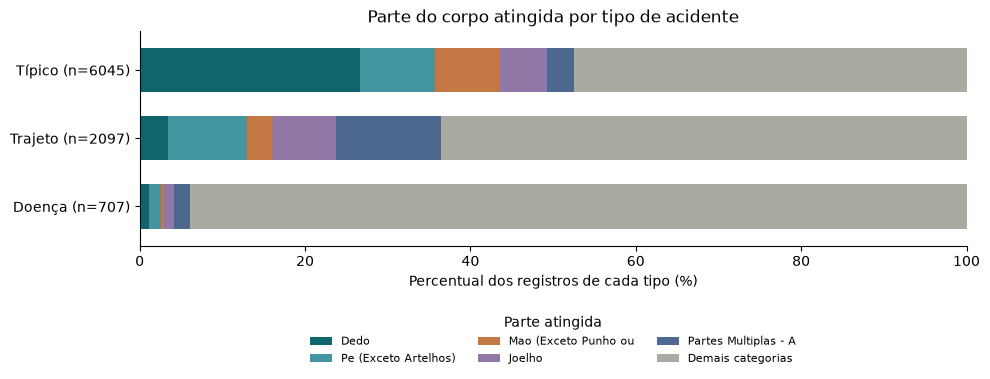

In [10]:
partes_principais = agrupar_principais(parte)
cruzamento = pd.crosstab(tipo.rename("Tipo de acidente"), partes_principais.rename("Parte atingida"))
ordem = [nome for nome in partes_principais.value_counts().index if nome != "Demais categorias"]
if "Demais categorias" in cruzamento:
    ordem.append("Demais categorias")
cruzamento = cruzamento[ordem]
totais_tipo = cruzamento.sum(axis=1)
display(cruzamento.assign(Total=totais_tipo))

percentuais = 100 * cruzamento.div(totais_tipo, axis=0)
cores = ["#10656c", "#4396a1", "#c47843", "#9178a6", "#4c6790", "#aaa9a2", "#dfd2ba"]
ax = percentuais.plot.barh(stacked=True, color=cores[:len(ordem)], figsize=(10, 4.2), width=0.65)
ax.set(xlim=(0, 100), xlabel="Percentual dos registros de cada tipo (%)", ylabel="",
       title="Parte do corpo atingida por tipo de acidente")
ax.spines[["top", "right"]].set_visible(False)
ax.set_yticks(range(len(totais_tipo)), [f"{tipo_nome} (n={total})" for tipo_nome, total in totais_tipo.items()])
ax.legend(title="Parte atingida", loc="upper center", bbox_to_anchor=(0.5, -0.28),
          ncol=3, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

,Todas as linhas,% de todas,Linhas distintas,% das distintas
Mês do acidente,,,,
Jan,1136,12.84,1115,15.48
Fev,1122,12.68,1102,15.30
Mar,1301,14.70,1264,17.55
Abr,1256,14.19,1202,16.69
Mai,1608,18.17,1305,18.12
Jun,2426,27.42,1213,16.84


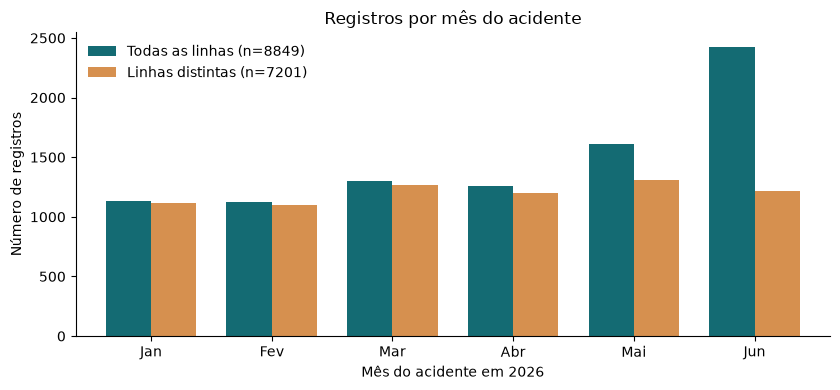

In [11]:
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"]
mensal = comparar(ocorrencia.dt.month).reindex(range(1, 7), fill_value=0)
mensal.index = pd.Index(meses, name="Mês do acidente")
display(mensal)
ax = mensal[["Todas as linhas", "Linhas distintas"]].plot.bar(
    figsize=(8.5, 4), color=["#146b73", "#d6904f"], rot=0, width=0.75)
ax.set(title="Registros por mês do acidente", xlabel="Mês do acidente em 2026",
       ylabel="Número de registros")
ax.legend([f"Todas as linhas (n={n})", f"Linhas distintas (n={n_distintas})"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [12]:
dias = (emissao.loc[base.index] - ocorrencia).dt.days
faixas_prazo = ["Antes do acidente", "No mesmo dia", "1 a 7 dias", "8 a 30 dias", "Mais de 30 dias"]
prazo = pd.cut(dias, [-float("inf"), -1, 0, 7, 30, float("inf")], labels=faixas_prazo)
prazo = prazo.cat.add_categories(["Sem intervalo válido"]).fillna("Sem intervalo válido")
display(comparar(prazo).reindex([*faixas_prazo, "Sem intervalo válido"]))
resumo_dias = pd.concat({"Todas as linhas": dias.describe(percentiles=[.5, .9, .99]),
                         "Linhas distintas": dias[uma_por_combinacao].describe(percentiles=[.5, .9, .99])}, axis=1)
display(resumo_dias.rename(index={"count": "Intervalos válidos", "min": "Mínimo (dias)", "50%": "Mediana (dias)",
                                  "90%": "P90 (dias)", "99%": "P99 (dias)", "max": "Máximo (dias)"})
        .drop(index=["mean", "std"]).round(1))

,Todas as linhas,% de todas,Linhas distintas,% das distintas
Antes do acidente,0,0.00,0,0.00
No mesmo dia,461,5.21,388,5.39
1 a 7 dias,5214,58.92,4343,60.31
8 a 30 dias,2375,26.84,1923,26.70
Mais de 30 dias,799,9.03,547,7.60
Sem intervalo válido,0,0.00,0,0.00


,Todas as linhas,Linhas distintas
Intervalos válidos,8849.0,7201.0
Mínimo (dias),0.0,0.0
Mediana (dias),5.0,4.0
P90 (dias),28.0,25.0
P99 (dias),120.0,102.0
Máximo (dias),191.0,191.0
